### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [15]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [16]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [17]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [18]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    arr = np.asarray(data[1].data)
    arr = arr.byteswap().view(arr.dtype.newbyteorder('='))
    df = pd.DataFrame(arr)
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [19]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [20]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [21]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23822 entries, 0 to 23821
Data columns (total 78 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   objno_deep2      23822 non-null  int32  
 1   ra_deep2         23822 non-null  float64
 2   dec_deep2        23822 non-null  float64
 3   magb             23822 non-null  float32
 4   magr             23822 non-null  float32
 5   magi             23822 non-null  float32
 6   pgal             23822 non-null  float32
 7   sfd_ebv          23822 non-null  float32
 8   class            23822 non-null  object 
 9   subclass         23822 non-null  object 
 10  objname          23822 non-null  object 
 11  maskname         23822 non-null  object 
 12  slitname         23822 non-null  object 
 13  date             23822 non-null  object 
 14  mjd              23822 non-null  float32
 15  z_raw            23822 non-null  float32
 16  zhelio           23822 non-null  float32
 17  z_err       

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [22]:
features= ['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']
df[features].describe()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
count,23822.000000,23822.000000,23822.000000,23822.000000,23822.000000,23822.000000
mean,23.030009,22.054381,21.459569,21.018872,20.791391,-36.894099
std,21.661775,20.858882,20.795278,20.786143,20.782124,60.688602
min,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000
25%,23.673291,23.239957,22.596881,22.013467,21.711539,-99.000000
50%,24.320863,23.911515,23.414908,22.911102,22.629739,19.360840
75%,25.003412,24.437682,23.893222,23.495253,23.288285,22.468418
max,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000


In [23]:
target=['zhelio']
df[target].describe()

,zhelio
count,23822.000000
mean,0.714948
std,0.417606
min,-0.078525
25%,0.393856
50%,0.688211
75%,0.983307
max,4.500611


### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [24]:
model = RandomForestRegressor(random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_all = df[target[0]]

In [25]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [26]:
%%time
scores = cross_validate(model, df[features], y_all, cv=cv, scoring='r2', return_train_score=True)
scores

CPU times: user 48.5 s, sys: 315 ms, total: 48.8 s
Wall time: 48.9 s


{'fit_time': array([ 8.91103745,  8.50238395,  8.67455339, 10.57606387, 10.31332374]),
 'score_time': array([0.08293796, 0.08176994, 0.08644128, 0.10161757, 0.11528611]),
 'test_score': array([0.33916582, 0.30227986, 0.28793788, 0.32562499, 0.30028187]),
 'train_score': array([0.87835357, 0.87569793, 0.87701023, 0.87524366, 0.87527322])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [27]:
promedio_train = np.mean(scores['train_score'])
promedio_test = np.mean(scores['test_score'])

std_train = np.std(scores['train_score'])
std_test = np.std(scores['test_score'])

print("Promedio Train:", promedio_train, "Std Train:", std_train)
print("Promedio Test:", promedio_test, "Std Test:", std_test)

Promedio Train: 0.8763157209411883 Std Train: 0.0012044049189652553
Promedio Test: 0.31105808606944596 Std Test: 0.018600900309680094


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**


El $R^{2}$ promedio en entrenamiento es alto (0.876), mientras que en prueba es mucho más bajo (0.311). El modelo se ajusta muy bien a los datos de entrenamiento pero no generaliza, por lo que estaría haciendo un sobreajuste, indicando una alta varianza.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [28]:
ypred = cross_val_predict(model, df[features], df[target], cv=cv)

/home/ivanf/anaconda3/lib/python3.13/site-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/ivanf/anaconda3/lib/python3.13/site-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/ivanf/anaconda3/lib/python3.13/site-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/ivanf/anaconda3/lib/python3.13/site-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the

(0.0, 3.0)

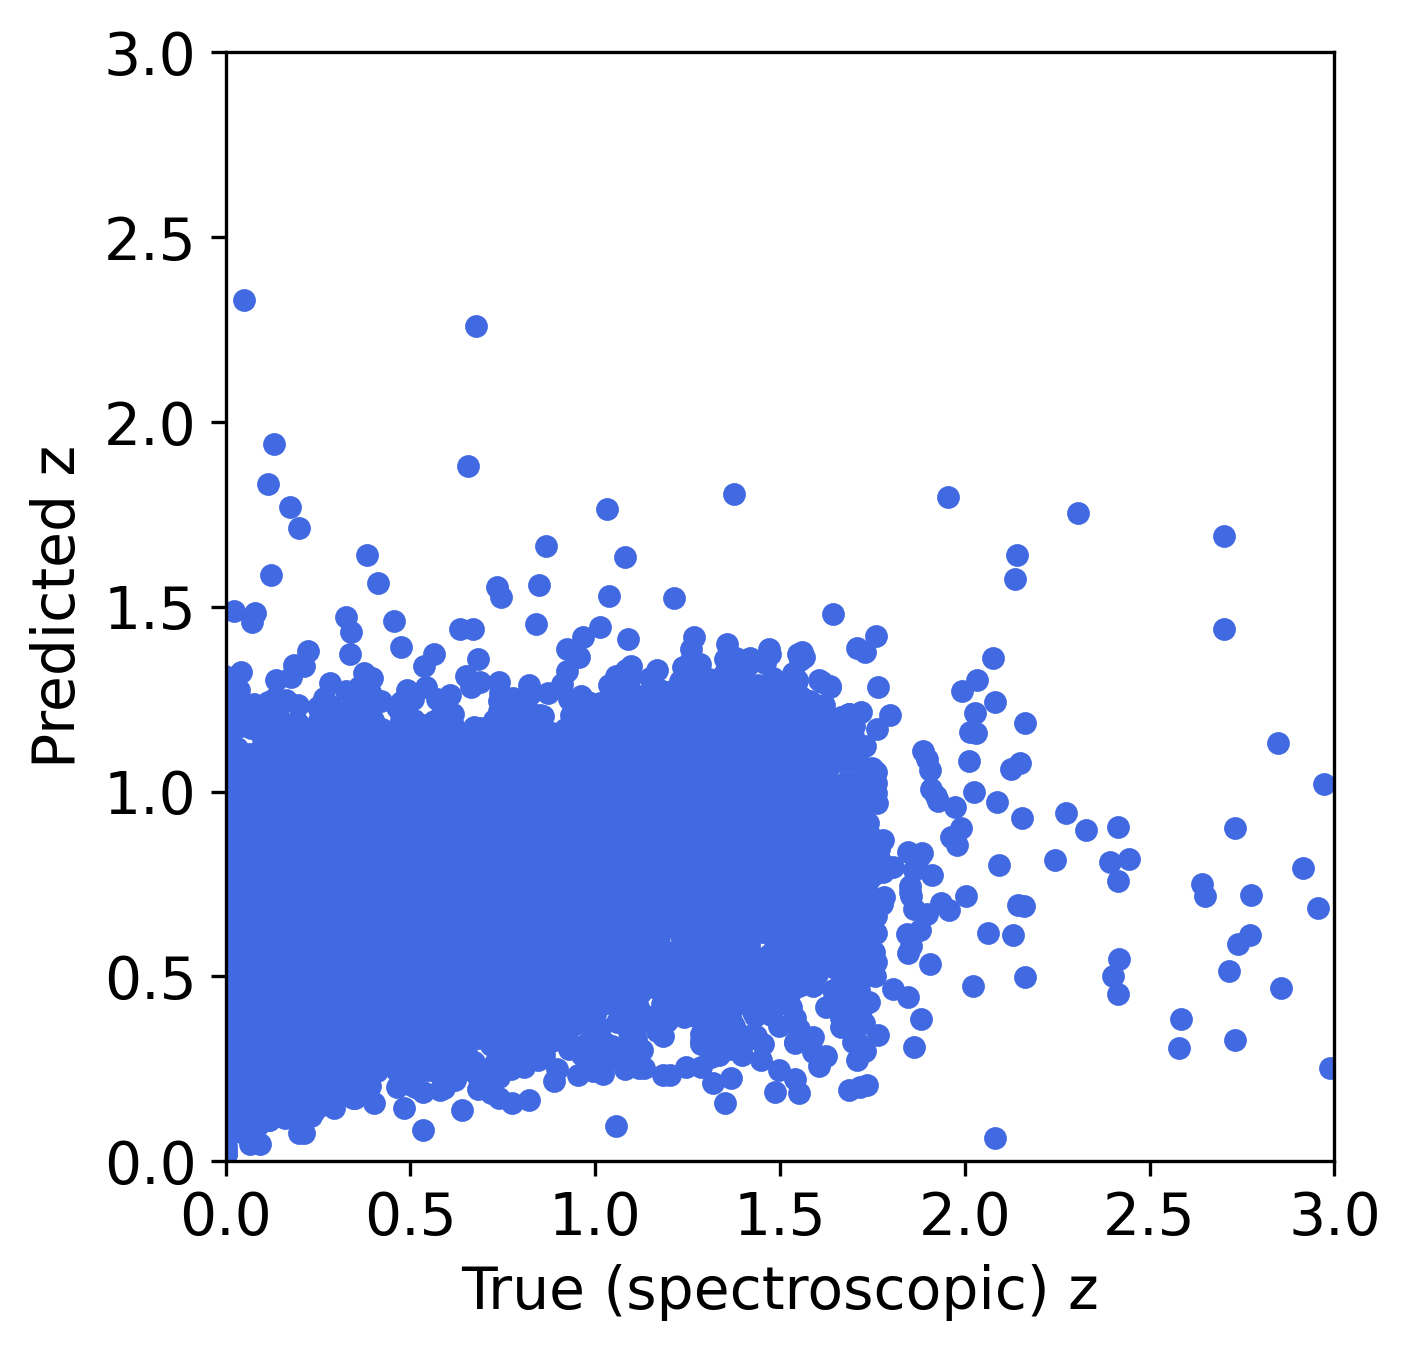

In [29]:
plt.scatter(df[target], ypred, s=20, c='royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

No. En la figura del paper se puede visualizar facilmente una relacion tal que $z_{phot} = z_{spec}$. El gráfico que se obtiene en este notebook vemos que hay mucha disperción, puntos con z real alto y el modelo produce z bajo y viceversa.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

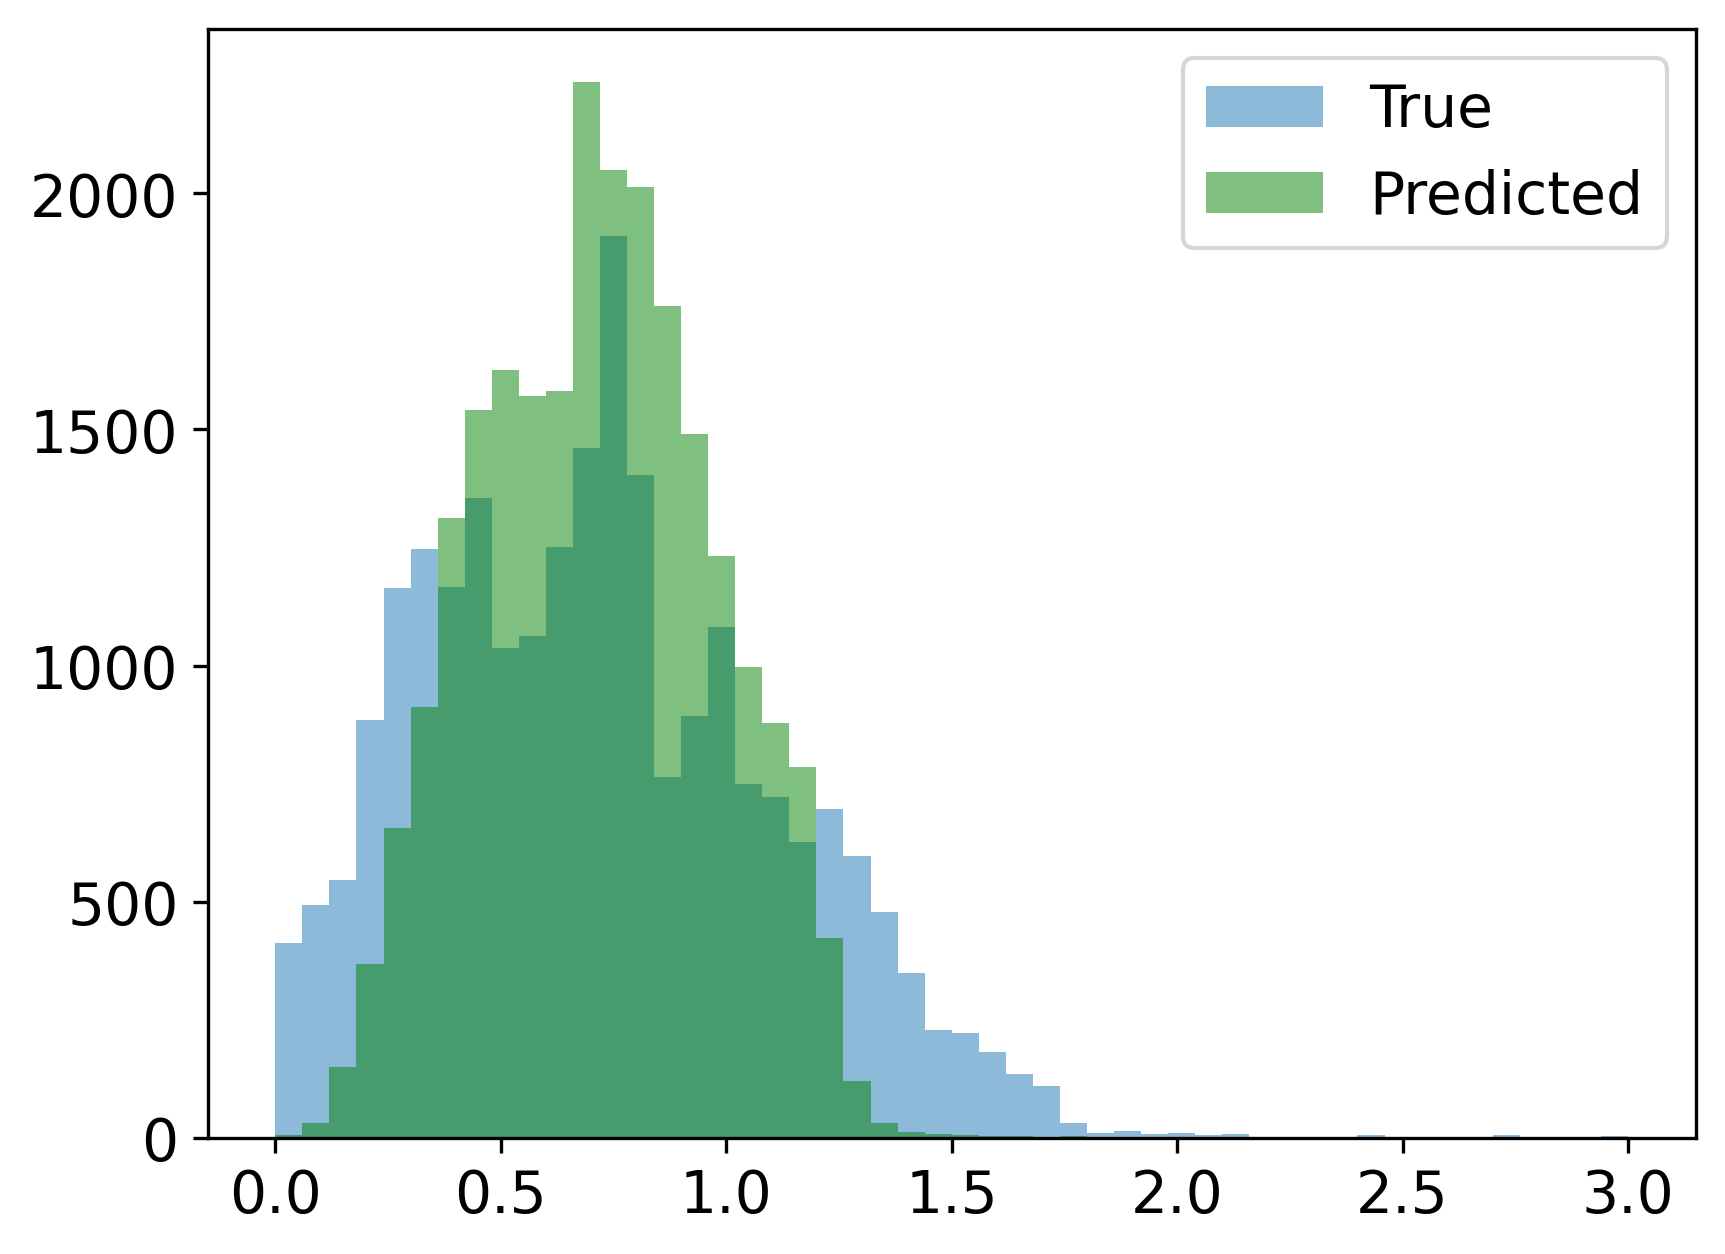

In [30]:
plt.hist(df[target],bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14)

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [31]:
z_spec = np.asarray(df[target]).ravel()
z_phot = np.asarray(ypred).ravel()
delta_z = z_phot - z_spec

sigma_NMAD = 1.48*np.median(np.abs(delta_z/(1+z_spec)))
outliers = np.where(np.abs(delta_z/(1+z_spec)) > 0.15)[0]
eta = len(outliers) / len(z_spec)


print("sigma_NMAD =", sigma_NMAD)
print("Fracción de outliers = %.1f%%" % (100 * eta))

sigma_NMAD = 0.07409954646856354
Fracción de outliers = 25.6%


Obtenemos un $\sigma_{NMAD} = 0.074$ y una fracción de outliers de $\eta = 25.6%$, resultado que, comparado con el paper es muchisimo peor. (paper: $\sigma_{NMAD} = 0.018$ y $\eta = 4.7$% para Deep). Podríamos decir que una de cuatro galaxias son consideradas outliers, claramente el modelo necesita ser mejorado al igual los datos. 

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [32]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False)

In [33]:
len(np.unique(sel))

sel

array([ 8379,   851,  8321, ...,  2441, 11704, 21978])

Y creamos nuestro nuevo dataset más pequeño

In [34]:
print(type(features), len(features))
print(features[:3])

<class 'list'> 6
['u_apercor', 'g_apercor', 'r_apercor']


In [35]:
X = df[features]

X

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980
...,...,...,...,...,...,...
23817,25.255430,25.056985,24.334668,24.383588,24.093228,-99.000000
23818,25.430378,24.728811,24.308648,24.014960,24.286921,-99.000000
23819,24.284426,24.378531,24.250438,23.943026,23.373493,-99.000000
23820,24.522067,24.366465,23.722660,23.457544,23.267684,-99.000000


In [36]:
seld = X.iloc[sel]
selt = df[target[0]].iloc[sel]

seld, selt

(       u_apercor  g_apercor  r_apercor  i_apercor  z_apercor  y_apercor
 8379   24.723094  23.726816  22.623313  21.518826  21.153211  20.966678
 851    24.589622  24.083354  23.769649  23.820287  23.578514 -99.000000
 8321   21.766006  21.077845  20.858898  20.770052  20.707456  20.807298
 18005  25.799440  25.721373  25.274365  24.810726  24.521166 -99.000000
 9428   24.979593  24.304614  23.938659  23.757910  23.705293  23.777003
 ...          ...        ...        ...        ...        ...        ...
 16305  26.248334  25.306520  24.306344  23.189810  22.763466 -99.000000
 9541   21.323773  20.855031  20.118920  19.902448  19.744263  19.662522
 2441   25.457507  25.545409  23.928893  22.972536  22.067877  21.854648
 11704  26.270150  25.464956  24.955723  24.173668  23.733777 -99.000000
 21978  24.353686  23.686477  23.351468  23.160881  23.236296 -99.000000
 
 [5000 rows x 6 columns],
 8379     0.749476
 851     -0.002966
 8321     0.044208
 18005    0.673365
 9428     0.168238
 

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [37]:
littlescores = cross_validate(model, seld, selt, cv=cv, return_train_score=True)
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.2732960032031041), np.float64(0.8751444478936407))

Con el subset de 5000 galaxias obtenemos un $R^{2}$ para la prueba (0.27) y entrenamiento (0.88) bastante similares a los que se obtuvieron del dataset completo. Por lo que la posible solución es la optimizacion de hiperparámetros. 

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [38]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [68]:
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 
              'n_estimators':[50, 100, 200], 
              'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}
#... implemente el resto

In [40]:
%%time
#n_jobs = -1 para el uso de todos los cpus
grid = GridSearchCV(model, parameters, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid.fit(seld, selt)

CPU times: user 4.3 s, sys: 331 ms, total: 4.63 s
Wall time: 2min 27s


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_features': [None, 4, 2],
                         'max_leaf_nodes': [None, 100, 200],
                         'min_impurity_decrease': [0.1, 0.5, 0.0],
                         'min_samples_split': [10, 20, 100],
                         'n_estimators': [50, 100, 200]},
             return_train_score=True, scoring='r2')

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [41]:
scores = pd.DataFrame(grid.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)

In [42]:
scoresCV.iloc[0]

params              {'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...
mean_test_score                                                                                                 0.29417
std_test_score                                                                                                 0.033395
mean_train_score                                                                                               0.653066
Name: 104, dtype: object

In [43]:
print("Sin optimizar: R² test =", littlescores['test_score'].mean(), "±", littlescores['test_score'].std())
print("Optimizado:    R² test =", grid.best_score_, "±", grid.cv_results_['std_test_score'][grid.best_index_])

Sin optimizar: R² test = 0.2732960032031041 ± 0.04094910716696126
Optimizado:    R² test = 0.29416955901558833 ± 0.03339480022557402


### Mejoran los scores?

La mejora en $R^{2}$ de test es de 0.02, menor que la desviación estándar entre folds, por lo que no es significativa. Lo que si cambia es el $R^{2}$ de entrenamiento el cual el promedio baja cercano a 0.65, es decir el modelo optimizado tiene un menor sobreajuste, pero sigue sin poder realizar una buena generalización.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [44]:
mags = df[
    ['u_apercor',
     'g_apercor',
     'r_apercor',
     'i_apercor',
     'z_apercor',
     'y_apercor',
     'subaru_source',
     'cfhtls_source',
     'zquality']
     ]

In [45]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [46]:
mags.shape

(23822, 9)

In [47]:
#zquality - solo usa objetos con medición de redshift de buena calidad
mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [48]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data
#cfhtls_source = 0 corresponde a Deep
mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [49]:
mags = mags[mags > -10].dropna()
mags.shape

(6371, 9)

In [50]:
mags = mags[mags < 90].dropna()
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [51]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [52]:
sel_target = df.loc[sel_features.index, target[0]]
sel_target

1251     1.003391
1253     0.902251
1261     0.424234
1271     0.768991
1272     0.990972
           ...   
19949    1.473057
20131    0.990994
20134    0.370325
20135    0.370973
20136    0.733315
Name: zhelio, Length: 6307, dtype: float32

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [53]:
scores_new = cross_validate(model, sel_features, sel_target, cv=cv, return_train_score=True)

print("Train R²: %.3f ± %.3f" % (scores_new['train_score'].mean(), scores_new['train_score'].std()))
print("Test  R²: %.3f ± %.3f" % (scores_new['test_score'].mean(),  scores_new['test_score'].std()))

Train R²: 0.963 ± 0.003
Test  R²: 0.753 ± 0.081


In [54]:
ypred_new = cross_val_predict(model, sel_features, sel_target, cv=cv)

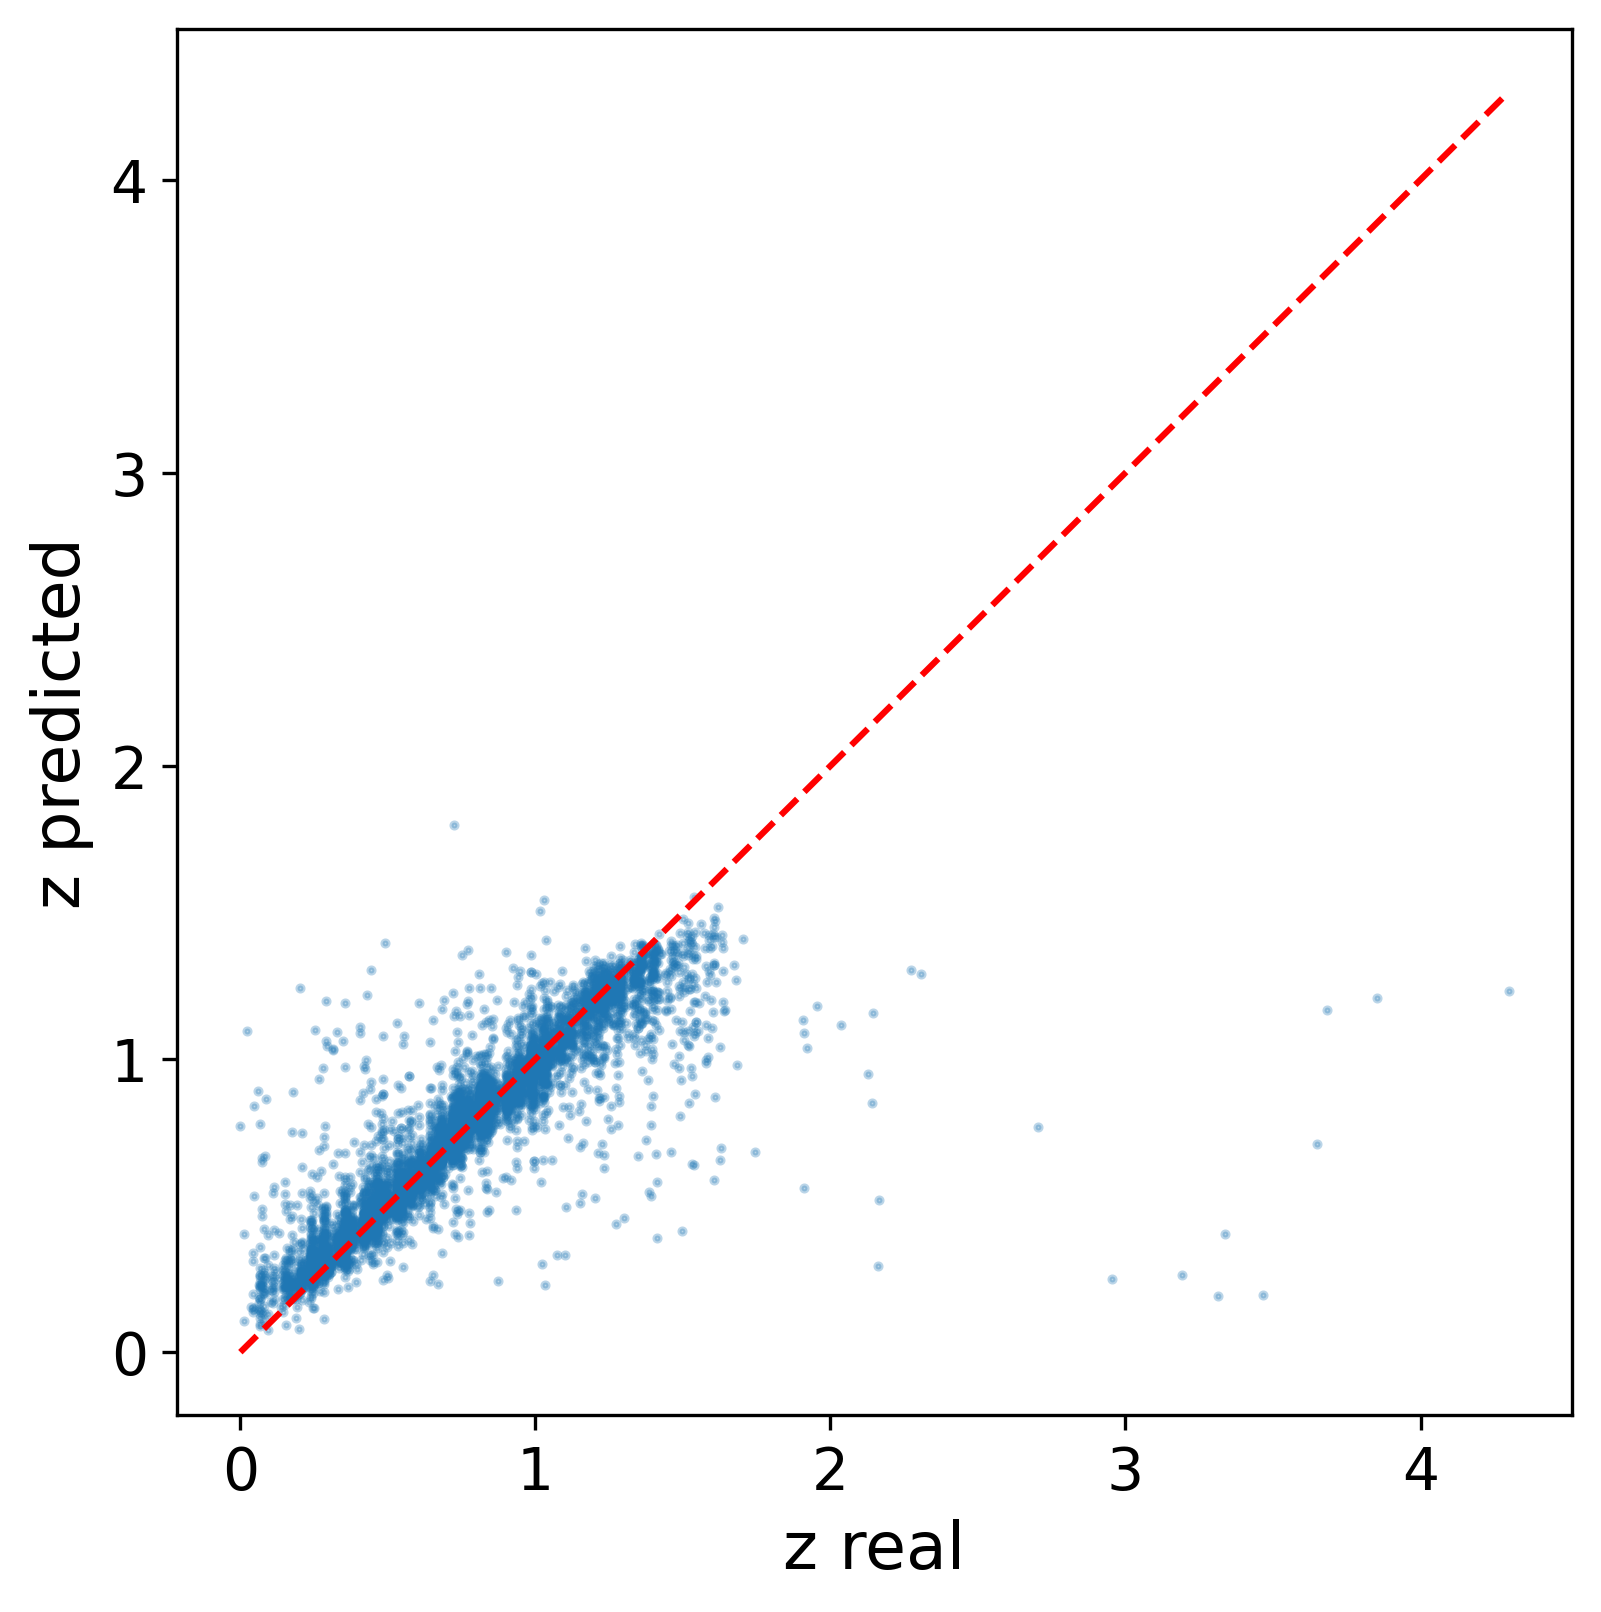

In [55]:
lims = [sel_target.min(), sel_target.max()]

plt.figure(figsize=(6, 6))
plt.scatter(sel_target, ypred_new, s=2, alpha=0.3)
plt.plot(lims, lims, 'r--')
plt.xlabel('z real')
plt.ylabel('z predicted')
plt.show()

In [56]:
z_spec_new = np.asarray(sel_target).ravel()
z_phot_new = np.asarray(ypred_new).ravel()
delta_z_new = z_phot_new - z_spec_new

sigma_NMAD_new = 1.48 * np.median(np.abs(delta_z_new / (1 + z_spec_new)))
outliers_new = np.where(np.abs(delta_z_new / (1 + z_spec_new)) > 0.15)[0]
eta_new = len(outliers_new) / len(z_spec_new)

print("sigma_NMAD =", sigma_NMAD_new)
print("Fracción de Outliers = %.1f%%" % (100 * eta_new))

sigma_NMAD = 0.03535815050418275
Fracción de Outliers = 5.6%


Quedarse con redshifts confiables, el campo CFHTLS Deep y objetos con fotometría válida en las 6 bandas mejora muchisimo el modelo, el $R^{2}$ de prueba sube (0.75) y los outliers bajan a 5.6%.  Los puntos en el grafico se pueden visualizar mejor en la recta aunque aún así, todavía existe la dispersión.

In [57]:
parameters_new = {'max_features': [None, 4, 2],
                  'min_samples_split': [2, 10, 20],
                  'n_estimators': [100, 200]}

In [58]:
%%time
grid_new = GridSearchCV(model, parameters_new, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid_new.fit(sel_features, sel_target)

CPU times: user 5.14 s, sys: 51.2 ms, total: 5.19 s
Wall time: 53 s


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_features': [None, 4, 2],
                         'min_samples_split': [2, 10, 20],
                         'n_estimators': [100, 200]},
             return_train_score=True, scoring='r2')

In [69]:
grid_new.best_params_

{'max_features': None, 'min_samples_split': 2, 'n_estimators': 200}

In [70]:
print("R² test optimizado = %.3f ± %.3f" % (grid_new.best_score_,
      grid_new.cv_results_['std_test_score'][grid_new.best_index_]))

R² test optimizado = 0.753 ± 0.081


In [60]:
ypred_new_best = cross_val_predict(grid_new.best_estimator_, sel_features, sel_target, cv=cv)

In [61]:
z_spec_best = np.asarray(sel_target).ravel()        # z real (espectroscópico)
z_phot_best = np.asarray(ypred_new_best).ravel()    # z predicho
delta_z_best = z_phot_best - z_spec_best

sigma_NMAD_best = 1.48 * np.median(np.abs(delta_z_best / (1 + z_spec_best)))
outliers_best = np.where(np.abs(delta_z_best / (1 + z_spec_best)) > 0.15)[0]
eta_best = len(outliers_best) / len(z_spec_best)

print("sigma_NMAD =", sigma_NMAD_best)
print("Fracción de outliers = %.1f%%" % (100 * eta_best))

sigma_NMAD = 0.03577376906455559
Fracción de outliers = 5.5%


Volver a optimizar los hiperparámetros no mejora el modelo: el $R^2$ de test se mantiene en 0.753 y $\sigma_{NMAD}$ y $\eta$ quedan prácticamente iguales. El mejor modelo es casi el modelo por defecto, lo que confirma que el desempeño depende más de los datos que de los hiperparámetros.

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada


En la sección 7, el paper no usa las magnitudes directamente, si no que usa los colores $u-g \, g-r \, r-i \, i-z \,z-y$ más la magnitud en la banda i. Por lo que podriamos trabajar con nuevos features e intentar mejorar los resultados aún más.

In [62]:
# Sección 7 del paper: 5 colores + magnitud en banda i como características
X_col = pd.DataFrame({
    'u-g': sel_features['u_apercor'] - sel_features['g_apercor'],
    'g-r': sel_features['g_apercor'] - sel_features['r_apercor'],
    'r-i': sel_features['r_apercor'] - sel_features['i_apercor'],
    'i-z': sel_features['i_apercor'] - sel_features['z_apercor'],
    'z-y': sel_features['z_apercor'] - sel_features['y_apercor'],
    'i':   sel_features['i_apercor'],
})
X_col.head()

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [67]:
scores_col = cross_validate(model, X_col, sel_target, cv=cv, return_train_score=True)
print("Train R²: %.3f ± %.3f" % (scores_col['train_score'].mean(), scores_col['train_score'].std()))
print("Test  R²: %.3f ± %.3f" % (scores_col['test_score'].mean(),  scores_col['test_score'].std()))

Train R²: 0.971 ± 0.002
Test  R²: 0.809 ± 0.072


In [64]:
ypred_col = cross_val_predict(model, X_col, sel_target, cv=cv)

z_spec_col = np.asarray(sel_target).ravel()
z_phot_col = np.asarray(ypred_col).ravel()
delta_z_col = z_phot_col - z_spec_col

sigma_NMAD_col = 1.48 * np.median(np.abs(delta_z_col / (1 + z_spec_col)))
outliers_col = np.where(np.abs(delta_z_col / (1 + z_spec_col)) > 0.15)[0]
eta_col = len(outliers_col) / len(z_spec_col)

print("sigma_NMAD =", sigma_NMAD_col)
print("Fracción de outliers = %.1f%%" % (100 * eta_col))

sigma_NMAD = 0.016174122637871192
Fracción de outliers = 3.6%


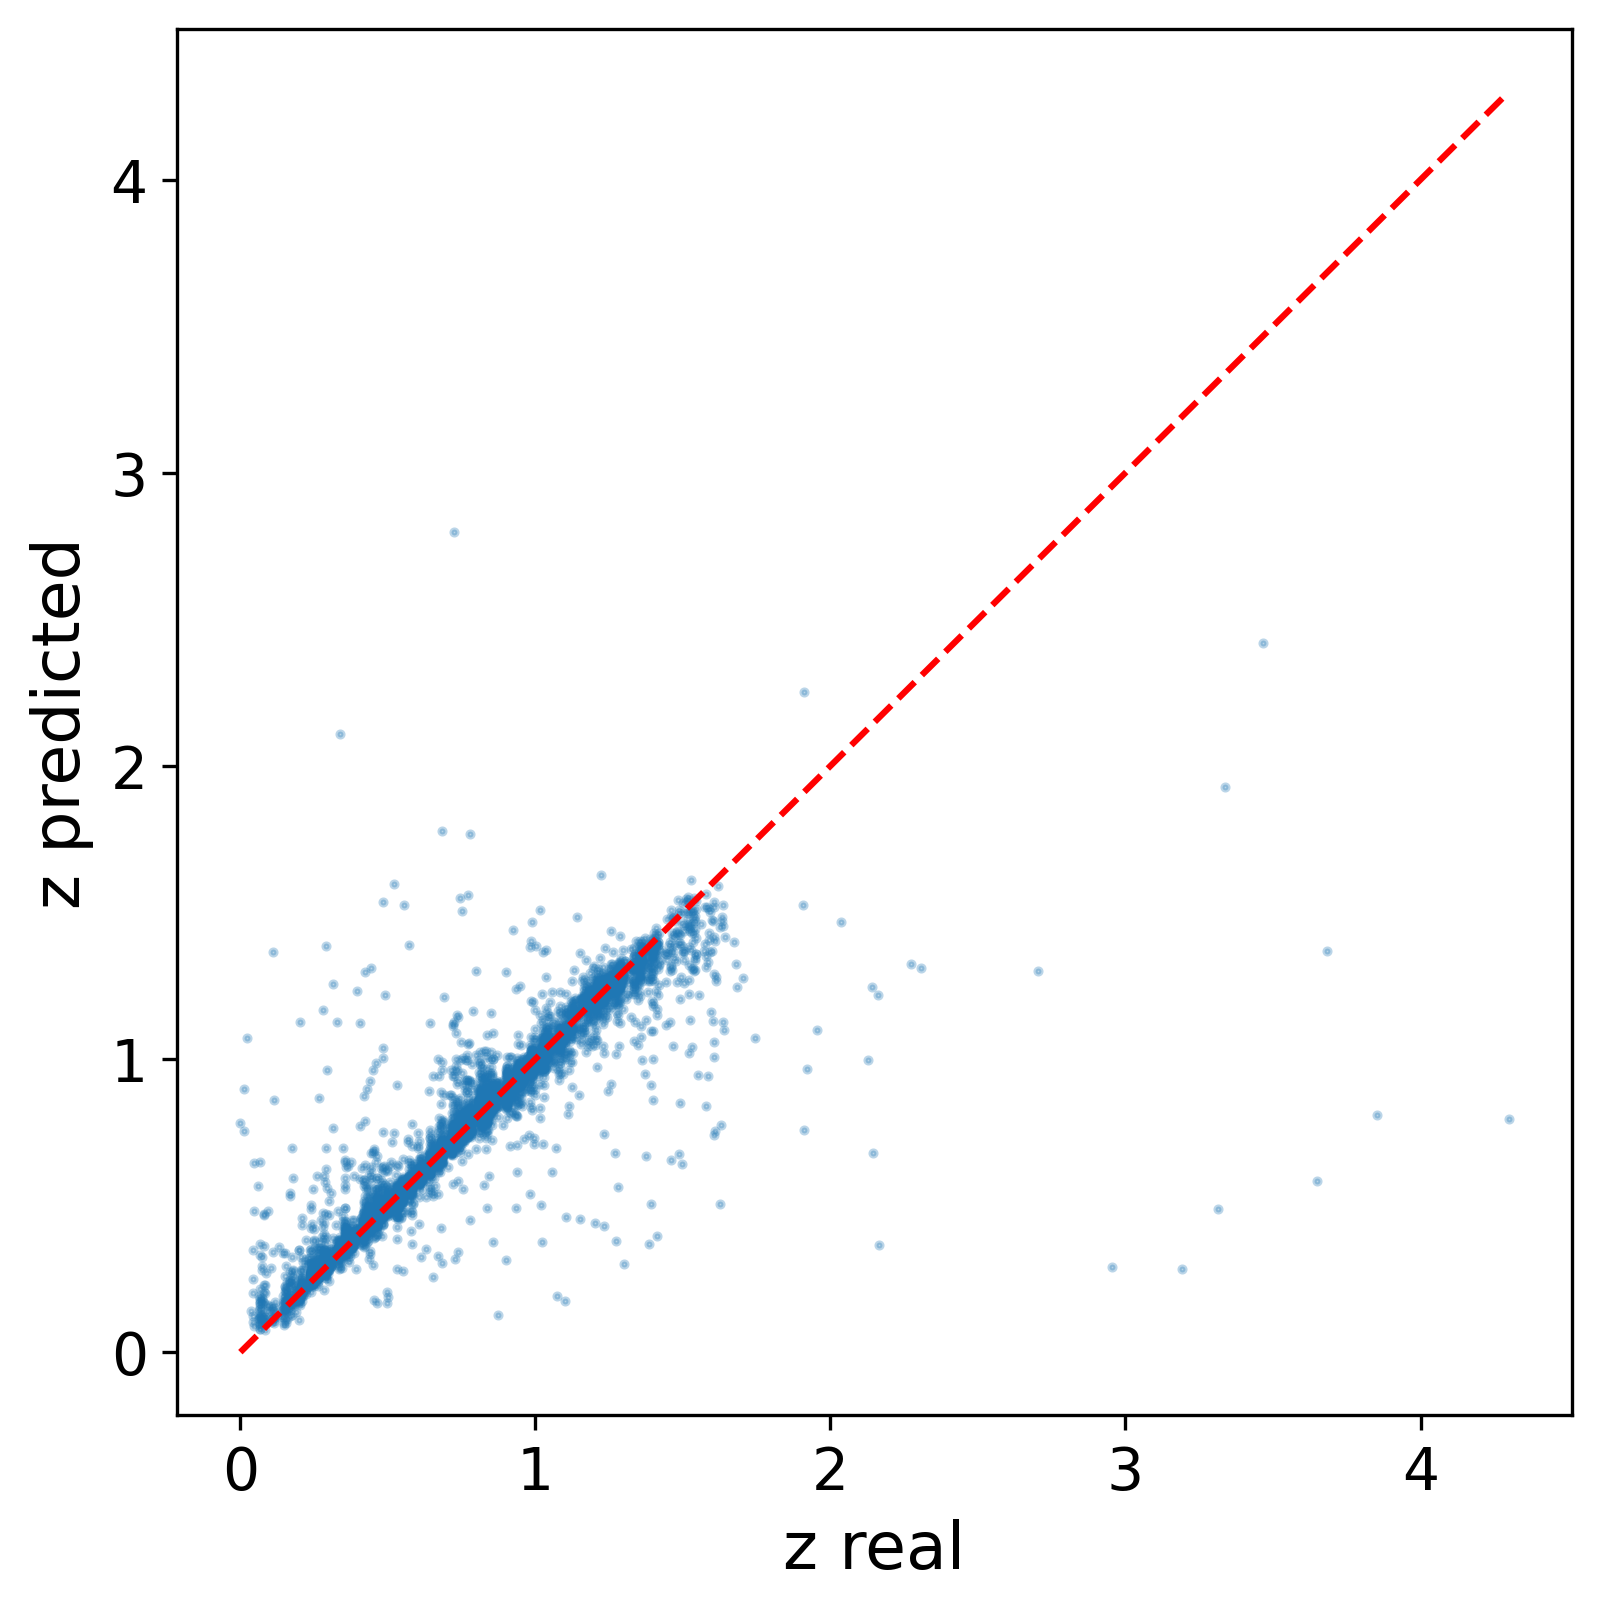

Exception ignored in: <function ResourceTracker.__del__ at 0x7dd4d658df80>
Traceback (most recent call last):
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7a4c37f8df80>
Traceback (most recent call last):
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/ivanf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ 

In [65]:
plt.figure(figsize=(6, 6))
plt.scatter(sel_target, ypred_col, s=2, alpha=0.3)
plt.plot(lims, lims, 'r--')
plt.xlabel('z real')
plt.ylabel('z predicted')
plt.show()

### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

Nuestro modelo final, con datos limpios y colores como características, obtiene $\sigma_{NMAD} = 0.016$ y $\eta = 3.6$%, comparables o incluso algo mejores que los del paper para el campo Deep ($\sigma_{NMAD} = 0.018$ y $\eta = 4.7$%). El paso más importante fue la selección de datos (redshifts confiables, campo Deep y fotometría válida en las 6 bandas), seguido del uso de colores en lugar de magnitudes. La optimización de hiperparámetros, en cambio, casi no tuvo efecto. Cabe destacar que el paper entrena con más objetos (DEEP2/3 y 3D-HST), mientras que en este notebook solo trabajamos con DEEP2 en el campo Deep, por lo que la comparación no es exacta. Aun así, es un buen resultado.